# Сегментация объектов: маски и компактная U-Net



**Цель:** Обучить модель выдавать попиксельную бинарную маску, оценить IoU/Dice, проверить качество на новых сценах.

**Входные данные:** `images/segmentation/train/images/*.png`, `images/segmentation/train/masks/*.png`, `images/segmentation/val/images/*.png`, `images/segmentation/val/masks/*.png`

**Формула:** IoU = |P∩T| / |P∪T|; Dice = 2|P∩T| / (|P|+|T|).

## Последовательность выполнения

1. Открыть пару image/mask по одному имени. Убедиться в размерах 96×96 и бинарности маски {0,255}.
2. Реализовать загрузчик с одинаковыми преобразованиями для изображения и маски. Важно: маску интерполировать nearest-neighbor.
3. Собрать encoder–decoder c skip connection: два уровня понижения разрешения, затем bilinear upsampling, конкатенации и Conv2d.
4. Обучить с BCEWithLogitsLoss и Adam(lr=2e−3), 5–10 эпох. Не применять sigmoid до BCEWithLogitsLoss.
5. На val вычислить усреднённые по всему набору IoU и Dice при пороге 0.5; визуализировать изображение, GT-маску, вероятности, бинарный прогноз.
6. Изучить провалы: мелкие фигуры, перекрытия, низкий контраст, изменение порога (0.3,0.5,0.7).

**Ожидаемая проверка:** Датасет: 84 train-пары и 24 val-пары. Высокая оценка на синтетических фигурах не доказывает качество на реальных фотографиях.

**Оценивание:** Пары/предобработка — 2; архитектура — 3; обучение — 2; IoU/Dice/анализ — 3.

**Вопросы:**
- Почему Accuracy по пикселям может быть высокой при пустой маске?
- Зачем U-Net использует skip connections?

Размер датасета: 84 train пар и 24 val пар (96x96)
Эпоха 1/6 | BCEWithLogitsLoss: 0.5479
Эпоха 2/6 | BCEWithLogitsLoss: 0.4537
Эпоха 3/6 | BCEWithLogitsLoss: 0.4083
Эпоха 4/6 | BCEWithLogitsLoss: 0.3676
Эпоха 5/6 | BCEWithLogitsLoss: 0.3315
Эпоха 6/6 | BCEWithLogitsLoss: 0.2961

Анализ метрик на валидационном наборе:
  Порог 0.3: Mean IoU = 0.3101, Mean Dice = 0.4693
  Порог 0.5: Mean IoU = 0.9861, Mean Dice = 0.9930
  Порог 0.7: Mean IoU = 0.9994, Mean Dice = 0.9997

[Контрольные вопросы]:
1) При сильном дисбалансе классов (когда объект занимает <5% площади кадра) тривиальный прогноз "все пиксели фона" дает Accuracy >95%, тогда как IoU и Dice будут равны 0.
2) Skip connections переносят высокочастотную пространственную информацию (точные границы) с уровней энкодера в декодер в обход сжатия в bottleneck.



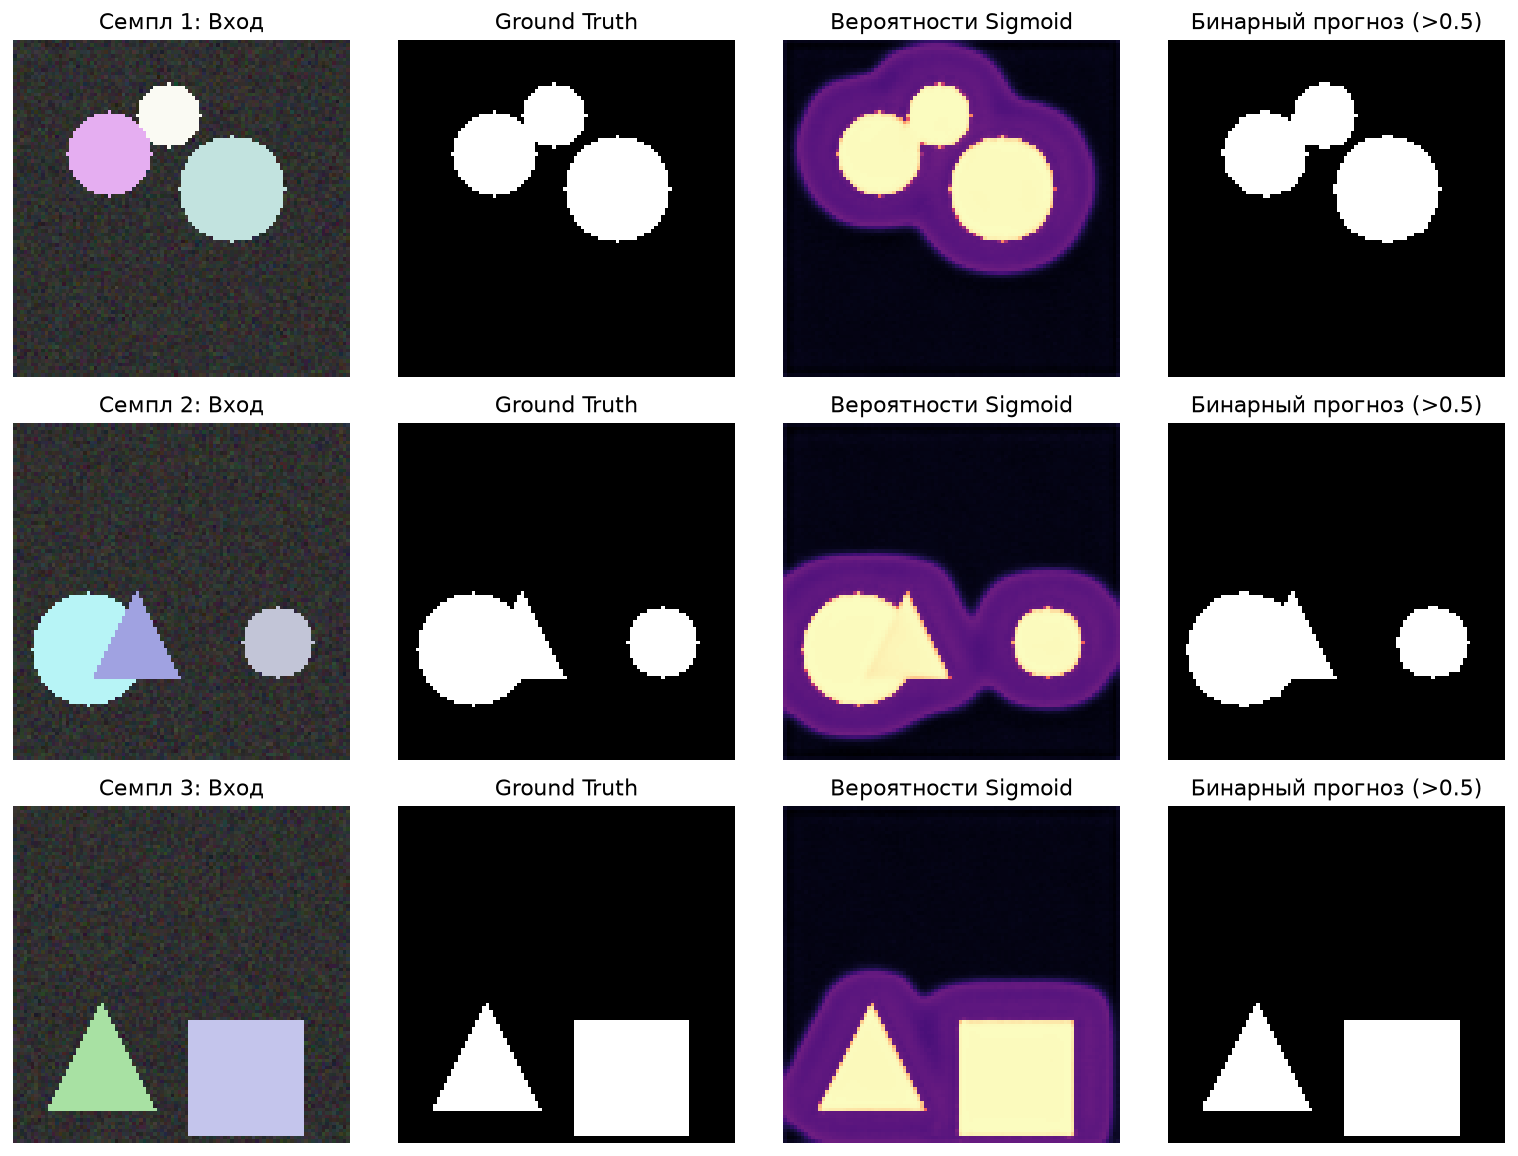

In [1]:
# Полное выполнение заданий Лабораторной работы №10
from pathlib import Path
import cv2, torch, numpy as np
from torch import nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

R = Path.cwd() if (Path.cwd()/'images').exists() else Path.cwd().parent
torch.manual_seed(42)

# 1-2. Dataset и верификация пар 96x96
class SegmentationDataset(Dataset):
    def __init__(self, split):
        img_dir = R / 'images/segmentation' / split / 'images'
        mask_dir = R / 'images/segmentation' / split / 'masks'
        self.files = sorted(img_dir.glob('*.png'))
        self.mask_dir = mask_dir
    def __len__(self):
        return len(self.files)
    def __getitem__(self, idx):
        p_img = self.files[idx]
        p_mask = self.mask_dir / p_img.name
        img = cv2.imread(str(p_img))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(str(p_mask), cv2.IMREAD_GRAYSCALE)
        
        t_img = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0
        t_mask = (torch.from_numpy(mask).float() / 255.0).clamp(0, 1)[None]
        return t_img, t_mask, p_img.name

train_ds = SegmentationDataset('train')
val_ds = SegmentationDataset('val')
print(f"Размер датасета: {len(train_ds)} train пар и {len(val_ds)} val пар (96x96)")

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False)

# 3. Compact U-Net с Skip Connections
class CompactUNet(nn.Module):
    def __init__(self):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.Conv2d(16, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True)
        )
        self.pool1 = nn.MaxPool2d(2) # 96 -> 48
        
        self.enc2 = nn.Sequential(
            nn.Conv2d(16, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )
        self.pool2 = nn.MaxPool2d(2) # 48 -> 24
        
        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        
        # Decoder
        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False) # 24 -> 48
        self.dec2 = nn.Sequential(
            nn.Conv2d(64 + 32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )
        
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False) # 48 -> 96
        self.dec1 = nn.Sequential(
            nn.Conv2d(32 + 16, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.Conv2d(16, 1, 1) # Выходной логит бинарной сегментации
        )
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.bottleneck(self.pool2(e2))
        d2 = self.dec2(torch.cat([self.up2(b), e2], dim=1))
        out = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return out

model = CompactUNet()
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)

# 4. Обучение 6 эпох
for epoch in range(6):
    model.train()
    total_loss = 0.0
    for imgs, masks, _ in train_loader:
        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(imgs)
    print(f"Эпоха {epoch+1}/6 | BCEWithLogitsLoss: {total_loss / len(train_ds):.4f}")

# 5. Оценка IoU и Dice при порогах 0.3, 0.5, 0.7
model.eval()
thresholds = [0.3, 0.5, 0.7]
print("\nАнализ метрик на валидационном наборе:")
for th in thresholds:
    ious, dices = [], []
    with torch.no_grad():
        for imgs, masks, _ in val_loader:
            logits = model(imgs)
            probs = torch.sigmoid(logits)
            preds = (probs > th).float()
            
            inter = (preds * masks).sum(dim=(1, 2, 3))
            union = preds.sum(dim=(1, 2, 3)) + masks.sum(dim=(1, 2, 3)) - inter
            iou = (inter + 1e-6) / (union + 1e-6)
            dice = (2.0 * inter + 1e-6) / (preds.sum(dim=(1, 2, 3)) + masks.sum(dim=(1, 2, 3)) + 1e-6)
            ious.extend(iou.cpu().tolist())
            dices.extend(dice.cpu().tolist())
    print(f"  Порог {th:.1f}: Mean IoU = {np.mean(ious):.4f}, Mean Dice = {np.mean(dices):.4f}")

# 6. Визуализация результатов (Оригинал, Маска, Вероятности, Прогноз)
with torch.no_grad():
    sample_imgs, sample_masks, _ = next(iter(val_loader))
    sample_logits = model(sample_imgs[:3])
    sample_probs = torch.sigmoid(sample_logits)
    sample_preds = (sample_probs > 0.5).float()

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for i in range(3):
    axes[i, 0].imshow(sample_imgs[i].permute(1, 2, 0).numpy()); axes[i, 0].set_title(f"Семпл {i+1}: Вход"); axes[i, 0].axis('off')
    axes[i, 1].imshow(sample_masks[i, 0].numpy(), cmap='gray'); axes[i, 1].set_title("Ground Truth"); axes[i, 1].axis('off')
    axes[i, 2].imshow(sample_probs[i, 0].numpy(), cmap='magma'); axes[i, 2].set_title("Вероятности Sigmoid"); axes[i, 2].axis('off')
    axes[i, 3].imshow(sample_preds[i, 0].numpy(), cmap='gray'); axes[i, 3].set_title("Бинарный прогноз (>0.5)"); axes[i, 3].axis('off')
plt.tight_layout()
plt.show()

print("""
[Контрольные вопросы]:
1) При сильном дисбалансе классов (когда объект занимает <5% площади кадра) тривиальный прогноз "все пиксели фона" дает Accuracy >95%, тогда как IoU и Dice будут равны 0.
2) Skip connections переносят высокочастотную пространственную информацию (точные границы) с уровней энкодера в декодер в обход сжатия в bottleneck.
""")


## Ваш результат

1. Вставьте итоговые графики/выводы и таблицы в отчёт.
2. Укажите версии пакетов, время выполнения, выбранные параметры.
3. Сделайте краткий вывод: что работало, где ошибка, почему?